# OpenQASM 3 on the twins

QPUTwin accepts OpenQASM 2.0 and a practical subset of OpenQASM 3: typed qubit and bit declarations, gate definitions,
gate modifiers, classical conditions and mid-circuit measurement. This notebook runs each of them on the live stack, and
ends with the error messages a program gets when it uses something unsupported.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': '02f7e5c0c4f6:7:0b2c9c',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. A Bell pair in OpenQASM 3

`qubit[n]`, `bit[n]` and `c = measure q;` replace `qreg`, `creg` and `measure q -> c;`. The response reports which version was parsed.

parsed as OpenQASM 3.0 -> {'00': 1013, '11': 987}


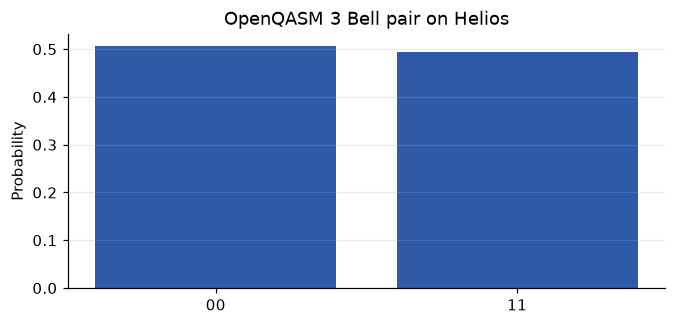

In [2]:
bell3 = """OPENQASM 3;
include "stdgates.inc";
qubit[2] q;
bit[2] c;
h q[0];
cx q[0], q[1];
c = measure q;
"""
r = run("quantinuum_helios", bell3, shots=2000)
print("parsed as OpenQASM", r["compilation"]["qasm_version"], "->", r["result"]["counts"])
plot_counts(r["result"]["counts"], "OpenQASM 3 Bell pair on Helios")
plt.show()

## 2. A parameterised gate definition

A `gate` with a parameter builds an XX rotation from `h`, `cx` and `rz`. On |00⟩ it gives P(11) = sin²(θ/2), which the twin reproduces for every angle.

In [3]:
def xx_program(theta):
    return f"""OPENQASM 3;
include "stdgates.inc";
gate xx_rot(t) a, b {{ h a; h b; cx a, b; rz(t) b; cx a, b; h a; h b; }}
qubit[2] q;
bit[2] c;
xx_rot({theta}) q[0], q[1];
c = measure q;
"""

thetas = np.linspace(0, np.pi, 7)
measured = [success(run("quantinuum_helios", xx_program(t), shots=20000), ["11"]) for t in thetas]
table = pd.DataFrame({"theta": thetas.round(3), "P(11) measured": np.round(measured, 4),
                      "sin^2(theta/2)": np.round(np.sin(thetas / 2) ** 2, 4)})
display(table)
assert np.allclose(table["P(11) measured"], table["sin^2(theta/2)"], atol=0.015)

,theta,P(11) measured,sin^2(theta/2)
0,0.000,0.0000,0.000
1,0.524,0.0669,0.067
2,1.047,0.2547,0.250
3,1.571,0.5042,0.500
4,2.094,0.7522,0.750
5,2.618,0.9352,0.933
6,3.142,1.0000,1.000


## 3. Gate modifiers: ctrl, inv and pow

`ctrl(2) @ x` is a Toffoli gate, `inv @ s` is S†, and `pow(2) @ t` is S. The truth table of the Toffoli comes back exactly, and the returned statevectors confirm the identities.

In [4]:
rows = []
for bits in range(8):
    prep = "".join(f"x q[{i}];\n" for i in range(3) if bits >> i & 1)
    prog = f"""OPENQASM 3;
include "stdgates.inc";
qubit[3] q;
bit[3] c;
{prep}ctrl(2) @ x q[0], q[1], q[2];
c = measure q;
"""
    out = run("quantinuum_helios", prog, shots=50)["result"]["counts"]
    rows.append({"input q2 q1 q0": format(bits, "03b"), "output": max(out, key=out.get)})
pd.DataFrame(rows)

,input q2 q1 q0,output
0,000,000
1,001,001
2,010,010
3,011,111
4,100,100
5,101,101
6,110,110
7,111,011


In [5]:
def state_after(gate_line):
    prog = f"""OPENQASM 3;
include "stdgates.inc";
qubit[1] q;
bit[1] c;
h q[0];
{gate_line}
c = measure q;
"""
    sv = run("quantinuum_helios", prog, shots=1, return_statevector=True)["result"]["statevector"]
    return np.array([complex(re, im) for re, im in sv])

for a, b in [("inv @ s q[0];", "sdg q[0];"), ("pow(2) @ t q[0];", "s q[0];"), ("pow(2) @ s q[0];", "z q[0];")]:
    print(f"{a:18s} equals {b:9s}:", np.allclose(state_after(a), state_after(b)))

inv @ s q[0];      equals sdg q[0];: True
pow(2) @ t q[0];   equals s q[0];  : True
pow(2) @ s q[0];   equals z q[0];  : True


## 4. Mid-circuit measurement and feed-forward

An active reset: put a qubit in superposition, measure it, and flip it back when it read 1. Ideally the second measurement is always 0. With device noise, the result shows how well each twin can reset a qubit this way.

In [6]:
active_reset = """OPENQASM 3;
include "stdgates.inc";
qubit[1] q;
bit[2] c;
h q[0];
c[0] = measure q[0];
if (c[0] == 1) { x q[0]; }
c[1] = measure q[0];
"""
rows = []
for b in ALL_BACKENDS:
    ideal = run(b, active_reset, shots=4000)
    noisy = run(b, active_reset, shots=4000, noise=True)
    p0 = lambda r: sum(v for k, v in r["result"]["counts"].items() if k[0] == "0") / 4000
    rows.append({"twin": NAMES[b], "P(reset to 0), ideal": p0(ideal), "P(reset to 0), device noise": p0(noisy)})
pd.DataFrame(rows).set_index("twin").round(4)

,"P(reset to 0), ideal","P(reset to 0), device noise"
twin,,
Helios,1.0,0.9995
Forte,1.0,0.9888
Ankaa-3,1.0,0.9415
Emerald,1.0,0.9415
Heron r3,1.0,0.9938
Nighthawk,1.0,0.9728
Willow,1.0,0.9888


The first bit of each outcome (the leftmost character) is `c[1]`, the result after the reset.

## 5. Vendor-native gates are portable

Each vendor's native gates are available on every twin. A circuit written in Quantinuum's natives (`u1q`, `zzmax`) runs unchanged on all seven twins, which compile it into their own gate sets; the ideal distributions agree.

In [7]:
native_prog = HEADER + """qreg q[3];
creg c[3];
u1q(pi/2, 0) q[0];
zzmax q[0], q[1];
u1q(pi/2, pi/2) q[1];
zzmax q[1], q[2];
u1q(pi/3, 0) q[2];
measure q -> c;
"""
reference = run("quantinuum_helios", native_prog, shots=100000)["result"]["counts"]
rows = []
for b in ALL_BACKENDS:
    r = run(b, native_prog, shots=100000)
    rows.append({"twin": NAMES[b], "native gates": r["compilation"]["native_gate_histogram"],
                 "Hellinger fidelity to Helios": round(hellinger(reference, r["result"]["counts"]), 4)})
pd.DataFrame(rows).set_index("twin")

,native gates,Hellinger fidelity to Helios
twin,,
Helios,"{'u1q': 3, 'zzmax': 2}",1.0
Forte,"{'gpi2': 10, 'ms': 4, 'rz': 7}",1.0
Ankaa-3,"{'cz': 4, 'rx': 7, 'rz': 6}",1.0
Emerald,"{'cz': 4, 'prx': 7, 'rz': 3}",1.0
Heron r3,"{'cz': 4, 'rz': 6, 'sx': 6, 'x': 1}",1.0
Nighthawk,"{'cz': 4, 'rz': 6, 'sx': 6, 'x': 1}",1.0
Willow,"{'cz': 4, 'phased_xz': 7}",1.0


## 6. Errors that say exactly what is wrong

Unsupported or malformed programs are rejected before anything runs, with the error type, a message and machine-readable details such as the line and column.

In [8]:
bad_programs = {
    "missing semicolon": HEADER + "qreg q[1];\nh q[0]\nmeasure q[0] -> c[0];\n",
    "index out of range": HEADER + "qreg q[2];\ncreg c[2];\nh q[5];\n",
    "unsupported for loop": """OPENQASM 3;
include "stdgates.inc";
qubit[2] q;
for int i in [0:1] { h q[i]; }
""",
}
for name, prog in bad_programs.items():
    r = run("quantinuum_helios", prog)
    e = r["error"]
    print(f"{name:22s} HTTP {r['http_status']}  {e['type']}: {e['message']}  {e.get('details', {})}")

missing semicolon      HTTP 400  QASMSyntaxError: expected ';' after gate call, found 'measure' (line 5, col 1)  {'found': 'measure', 'line': 5, 'col': 1}
index out of range     HTTP 400  QASMSemanticError: index 5 out of range for register 'q' of size 2 (line 5)  {'register': 'q', 'index': 5, 'size': 2, 'line': 5}
unsupported for loop   HTTP 400  UnsupportedFeatureError: OpenQASM 3 'for' statements are outside the supported subset (line 4)  {'feature': 'for', 'line': 4}


## Takeaways

- OpenQASM 3 declarations, gate definitions, modifiers and classical conditions run on every twin.
- Vendor-native gates are portable: every twin compiles them into its own gate set.
- Unsupported features fail fast with a precise, typed error.